In [1]:
import torchvision.transforms as transforms
from torchvision.io import read_image
import matplotlib.pyplot as plt
from itertools import chain
import random
import os

In [37]:
DATASET = "/home/tteuz/Desktop/mestrado/datasets/siamese/PKLot"

In [38]:
subsets = os.listdir(DATASET)

dates = []
for subset in subsets:
    dates.extend([f"{subset}/{date}" for date in os.listdir(f"{DATASET}/{subset}")])

images = []
for date in dates:
    images.extend([f"{DATASET}/{date}/{image_path}" for image_path in os.listdir(f"{DATASET}/{date}")])

In [60]:
image_path = random.choice(images)

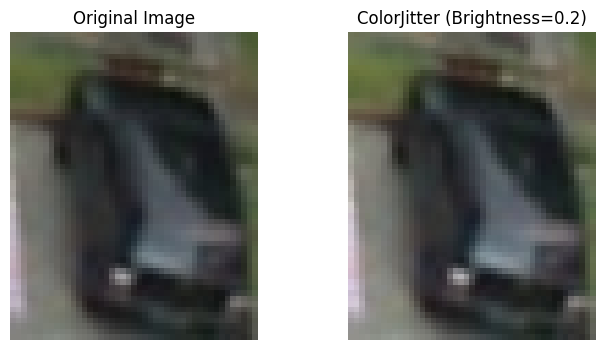

In [209]:
original_image = read_image(image_path).float() / 255.0

color_jitter = transforms.ColorJitter(brightness=0.2)
augmented_image = color_jitter(original_image)

def tensor_to_numpy(tensor):
    return tensor.permute(1, 2, 0).cpu().numpy()

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(tensor_to_numpy(original_image))
axes[0].set_title("Original Image")
axes[0].axis("off")

axes[1].imshow(tensor_to_numpy(augmented_image))
axes[1].set_title("ColorJitter (Brightness=0.2)")
axes[1].axis("off")

plt.show()

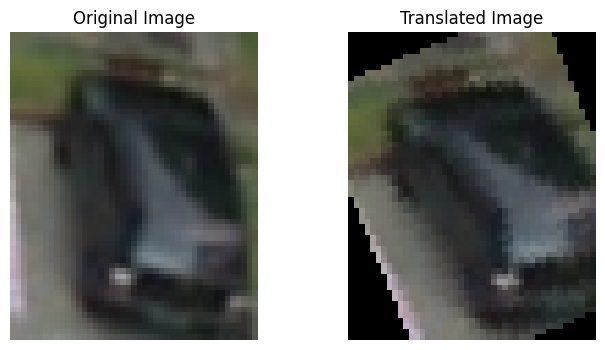

In [199]:
original_image = read_image(image_path).float() / 255.0

translate_transform = transforms.RandomAffine(degrees=25, translate=(0.1, 0.1))
augmented_image = translate_transform(original_image)

def tensor_to_numpy(tensor):
    return tensor.permute(1, 2, 0).cpu().numpy()

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(tensor_to_numpy(original_image))
axes[0].set_title("Original Image")
axes[0].axis("off")

axes[1].imshow(tensor_to_numpy(augmented_image))
axes[1].set_title("Translated Image")
axes[1].axis("off")

plt.show()